<center><b>CTS2000: Scripting for the Humanities</b></center>
<center>7-1: Basic Statistics for Text Analysis</center>

---

# Statistics for Text Analysis
### What do our counts actually mean?

---

## Overview

In the Montagu notebook we built a whole toolkit: we tokenized, removed stopwords, counted words with `FreqDist`, tagged parts of speech and lemmatized. We even ran `.describe()` on letter lengths and noticed that the standard deviation was almost as large as the mean.

That left us with a lot of numbers. This notebook is about what to **do** with them. *Is 800 a lot?* *Compared to what?* *Is this author's style unusual, or is this book just longer?* Statistics is the toolkit for turning counts into comparisons.

**What we'll cover:**

0. Setup: building a small corpus of Gothic fiction
1. Counts and distributions
2. Raw vs. relative frequency
3. The "typical" value: mean, median, mode
4. Spread: range, variance, standard deviation, quartiles
5. Seeing distributions: bar charts, histograms, boxplots
6. Zipf's law, the long tail, and logarithms
7. Lexical diversity: the type-token ratio and its traps
8. Standardising with z-scores (and a tiny authorship experiment)
9. Putting it together: statistics on POS tags
10. Practice challenges
11. Key points to remember

---

**Dataset:** six works of Gothic fiction from Project Gutenberg, 1818–1903.

| Title | Author | Year | Form | Gutenberg ID
|---|---|---|---|---|
| *Frankenstein* | Mary Shelley | 1818 | letters framing nested first-person narratives | 84 |
| *Carmilla* | Sheridan Le Fanu | 1872 | first-person account, a novella | 10007 |
| *Strange Case of Dr Jekyll and Mr Hyde* | Robert Louis Stevenson | 1886 | third-person, plus documents; a novella | 43 |
| *The Picture of Dorian Gray* | Oscar Wilde | 1890 | third-person, lots of dialogue | 174 |
| *Dracula* | Bram Stoker | 1897 | letters, diaries, telegrams, newspaper clippings | 345 |
| *The Jewel of Seven Stars* | Bram Stoker | 1903 | first-person, a mummy novel | 3781 |

Two things about this selection are on purpose. The texts have **very different lengths** (*Jekyll and Hyde* is about a sixth of *Dracula*), which will trip us up in useful ways. And there are **two novels by the same author**, which we'll need in Section 8.

---
## 0. Setup

### Imports

Almost everything here should look familiar from the Montagu notebook. There is one new import:

- `math`: Python's built-in maths module. We need it for square roots and logarithms.

In [1]:
import os
import re
import math
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

import nltk
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk import pos_tag, FreqDist

stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/mervetekgurler/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/mervetekgurler/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /Users/mervetekgurler/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/mervetekgurler/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [ ]:
with open("../../data/gothic/dracula.txt") as f:
    dracula = f.read()

print(dracula[:5000])

In [ ]:
print(dracula[-22000:])

### Getting the novels

Each file starts with a Gutenberg header and ends with a long licence. Both are marked with lines like `*** START OF THE PROJECT GUTENBERG EBOOK DRACULA ***` and `*** END OF ...`. We want only what's in between.

In [2]:
def strip_gutenberg(raw_text):
    """Keep only the text between Gutenberg's START and END markers."""
    start = re.search(r"\*\*\*\s*START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", raw_text, re.DOTALL)
    end = re.search(r"\*\*\*\s*END OF (THE|THIS) PROJECT GUTENBERG EBOOK", raw_text)
    text = raw_text[start.end():end.start()]
    text = text.replace("\r\n", "\n")   # Windows line endings -> normal line endings
    text = text.replace("_", " ")         # Gutenberg marks _italics_ with underscores
    return text.strip()

In [ ]:
len(dracula)

In [ ]:
len(strip_gutenberg(dracula))

In [ ]:
print(strip_gutenberg(dracula)[:1000])

In [ ]:
print(strip_gutenberg(dracula)[-1000:])

*Explanation*

- `strip_gutenberg()` uses two regular expressions (see the regex notebook) to find the START and END markers, then slices out everything in between, just like slicing a string.
- Why remove underscores? Gutenberg writes italics as `_like this_`. If we kept them, `word_tokenize` would produce tokens like `_like`, which `.isalpha()` would then throw away, and we'd silently lose every italicised word.

Now the list of books. Each entry is a dictionary, and a list of dictionaries turns straight into a DataFrame (remember `pd.DataFrame(languages_dict)` from the pandas notebook?).

In [3]:
books = [
    {"title": "Frankenstein",             "author": "Mary Shelley",           "year": 1818, "gutenberg_id": 84,    "filename": "frankenstein.txt"},
    {"title": "Carmilla",                 "author": "Sheridan Le Fanu",       "year": 1872, "gutenberg_id": 10007, "filename": "carmilla.txt"},
    {"title": "Jekyll and Hyde",          "author": "Robert Louis Stevenson", "year": 1886, "gutenberg_id": 43,    "filename": "jekyll_hyde.txt"},
    {"title": "Dorian Gray",              "author": "Oscar Wilde",            "year": 1890, "gutenberg_id": 174,   "filename": "dorian_grey.txt"},
    {"title": "Dracula",                  "author": "Bram Stoker",            "year": 1897, "gutenberg_id": 345,   "filename": "dracula.txt"},
    {"title": "The Jewel of Seven Stars", "author": "Bram Stoker",            "year": 1903, "gutenberg_id": 3781,  "filename": "seven_stars.txt"},
]

Title, author, year, and even the Project Gutenberg ID makes sense but why do we need the filenames? I downloaded the text files for these 6 works and added them to our repository in the `data/gothic` folder. We need to read these text files in and turn them into a dataframe. Keeping track of the filename helps us identify which file belongs to which work.

In [4]:
DATA_DIR = "../../data/gothic/" # why uppercase? 
for book in books:
    path = DATA_DIR + book["filename"]
    with open(path, encoding="utf-8-sig") as f:
        raw = f.read()
    book["text"] = strip_gutenberg(raw) # cleaning it up as we load
    print(f"Loaded {book['title']:<26} from {path}") # making sure that I actually accessed the correct book with the correct filename

Loaded Frankenstein               from ../../data/gothic/frankenstein.txt
Loaded Carmilla                   from ../../data/gothic/carmilla.txt
Loaded Jekyll and Hyde            from ../../data/gothic/jekyll_hyde.txt
Loaded Dorian Gray                from ../../data/gothic/dorian_grey.txt
Loaded Dracula                    from ../../data/gothic/dracula.txt
Loaded The Jewel of Seven Stars   from ../../data/gothic/seven_stars.txt


Why is DATA_DIR uppercased? Names in ALL CAPS are a Python convention for constants: values we set once at the top and don’t change afterwards, like file paths or settings. Python won’t stop you from changing them. The capitals are a signal to anyone reading the code (including future you) that these are constants

In [5]:
novels = pd.DataFrame(books)
novels.head()

,title,author,year,gutenberg_id,filename,text
0,Frankenstein,Mary Shelley,1818,84,frankenstein.txt,"Frankenstein;\n\nor, the Modern Prometheus\n\n..."
1,Carmilla,Sheridan Le Fanu,1872,10007,carmilla.txt,Carmilla\n\nby Joseph Sheridan Le Fanu\n\nCopy...
2,Jekyll and Hyde,Robert Louis Stevenson,1886,43,jekyll_hyde.txt,The Strange Case Of Dr. Jekyll And Mr. Hyde\n\...
3,Dorian Gray,Oscar Wilde,1890,174,dorian_grey.txt,The Picture of Dorian Gray\n\nby Oscar Wilde\n...
4,Dracula,Bram Stoker,1897,345,dracula.txt,DRACULA\n\n ...


Let's peek at the beginning of one text to check the cleaning worked.

In [ ]:
print(novels.loc[4, "text"][:1000])

Notice that a little cover material is still there (like a table of contents or title page). Real data is never perfectly clean. We'll see these leftovers show up in our statistics later, which is a useful lesson in itself.

In [ ]:
novels.to_csv("../../data/gothic/gothic_novels.csv", index=False) # let's save it so we can access it more easily later



### Tokenizing: the same recipe as the Montagu notebook

We tokenize with `word_tokenize`, keep only alphabetic tokens with `.isalpha()` and lowercase them. Then we store the token lists in a new column with `.apply()`, exactly as we did with `montagu['pos_tags']`.

In [7]:
def tokenize(text):
    """Lowercased, alphabetic-only word tokens."""
    return [t.lower() for t in word_tokenize(text) if t.isalpha()]

novels["tokens"] = novels["text"].apply(tokenize)
novels["n_tokens"] = novels["tokens"].apply(len)

novels[["title", "n_tokens"]]

,title,n_tokens
0,Frankenstein,75028
1,Carmilla,28270
2,Jekyll and Hyde,25642
3,Dorian Gray,79283
4,Dracula,161123
5,The Jewel of Seven Stars,89756


<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  Which is the longest text? The shortest? Roughly how many times longer is the longest than the shortest?
</div>

In [ ]:
longest = novels.loc[novels["n_tokens"].idxmax()]
shortest = novels.loc[novels["n_tokens"].idxmin()]

print(f"Longest:  {longest['title']} ({longest['n_tokens']:,} tokens)")
print(f"Shortest: {shortest['title']} ({shortest['n_tokens']:,} tokens)")
print(f"The longest text is {longest['n_tokens'] / shortest['n_tokens']:.1f} times longer than the shortest one")

---
## 1. Counts and distributions

### Counts are statistics

A **statistic** is a number that summarises some data. The simplest statistic is a **count**, so every time you ran `Counter`, `FreqDist` or `.value_counts()` you were already doing statistics.

Two words we'll use constantly:

- **Tokens**: every running word in a text.
- **Types**: the *distinct* words.

In *"the cat sat on the mat"* there are 6 tokens but only 5 types, because *the* is one type that occurs as two tokens.

In [ ]:
toy = "the cat sat on the mat and the dog sat on the cat".split()

print("tokens:", len(toy))
print("types: ", len(set(toy)))
FreqDist(toy).most_common()

### What is a distribution?

A **distribution** tells us *how often each value occurs*. The `FreqDist` above is literally a "frequency distribution": for each word (the value), how many times it occurs.

Distributions don't have to be about words. Here's another one: the **lengths** of the words in the opening sentence of *Frankenstein*'s first letter.

In [ ]:
sentence = "You will rejoice to hear that no disaster has accompanied the commencement of an enterprise which you have regarded with such evil forebodings"

word_lengths = pd.Series([len(w) for w in sentence.split()])
word_lengths.value_counts().reindex(range(1, 13), fill_value=0)

`.reindex(range(1, 13), fill_value=0)` makes sure every length from 1 to 12 gets a row, even lengths that never occur (like 1 or 6). Read this as: no words are 1 letter long, four words are 2 letters long (*to*, *no*, *of*, *an*), four are 3 letters long, seven are 4 letters long, and so on, up to one 12-letter word (*commencement*). Plotting it shows the **shape** of the distribution:

In [ ]:
word_lengths.value_counts().reindex(range(1, 13), fill_value=0).plot(kind="bar", color="darkred")
plt.xlabel("word length (letters)")
plt.ylabel("number of words")
plt.title("Word lengths in one sentence of Frankenstein")
plt.xticks(rotation=0)
plt.show()

Most of the rest of this notebook is about **describing distributions**: where their centre is (Section 3), how spread out they are (Section 4) and what shape they have (Sections 5 and 6).

---
## 2. Raw vs. relative frequency

Women are at the centre of a lot of Gothic fiction: the vampire Carmilla, Lucy and Mina in *Dracula*. A crude first question: **which of our texts talks about women the most?** As a rough proxy, let's count the pronoun *she*.

In [ ]:
novels["she"] = novels["tokens"].apply(lambda tokens: tokens.count("she"))

novels[["title", "n_tokens", "she"]].sort_values("she", ascending=False)

*Explanation*

`tokens.count("she")` is a plain Python list method: it counts how many times `"she"` appears in the list. `.apply()` with a `lambda` runs it on every novel's token list, just like our `word_count` lambda in the Montagu notebook.

<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  By raw count, <em>Dracula</em> wins easily. Is that a fair conclusion?
</div>

Not really. *Dracula* is more than five times as long as *Carmilla*. A longer book has more of *everything*: more *she*, more *the*, more commas. Raw counts mostly measure **length**.

### Normalising

The fix is to **normalise**: divide each count by the total number of tokens in that text. The result is a **relative frequency**, also called a **proportion**.

In [ ]:
novels["she_prop"] = novels["she"] / novels["n_tokens"]

novels[["title", "n_tokens", "she", "she_prop"]].sort_values("she_prop", ascending=False)

Now *Carmilla*, one of the shortest texts but the one with two women at its centre, comes first. *Dracula* drops to fourth.

Proportions of single words are tiny and hard to read (0.009904…). There are three common ways to make them readable, and they all mean the same thing:

| Format | Calculation | *Carmilla* |
|---|---|---|
| proportion | count / tokens | ≈ 0.0100 |
| percentage | proportion × 100 | ≈ 1.0% |
| per 10,000 words | proportion × 10,000 | ≈ 100 |

In plain terms: about 1 in every 100 words in Carmilla is she. All three rows say the same thing; they just use different units.

For individual words, "per 10,000" (or "per 1,000", or "per million" in very large corpora) is the most common convention.

In [ ]:
novels["she_per_10k"] = novels["she_prop"] * 10_000

novels[["title", "she", "she_per_10k"]].sort_values("she_per_10k", ascending=False).round(1)

> 💡 **Rule of thumb:** whenever you compare texts (or letters, chapters, authors) of different lengths, compare **relative** frequencies, not raw counts.

Did you notice *Jekyll and Hyde*? About 7 *she* per 10,000 words. Stevenson's novella is a world of men: lawyers, doctors, a butler. Even a crude count can point at something a literary critic would care about.

⚠️ A quick reality check. Counting the word she is a very rough proxy for “talking about women”, and it gets things wrong in both directions.

It misses a lot:

other words for women: her, woman, lady, girl, mother, sister…
names: Mina, Lucy, Carmilla, Sibyl…
women who narrate their own story. In Carmilla, Laura tells the whole story as I. In Dracula, Mina writes her own journal. Neither shows up in a count of she.

It also counts things that aren’t women:

ships, which English often calls she (including the Demeter, the ship that brings Dracula to England)
sometimes animals, countries or objects

So the numbers tell us something about how often the word she appears, not about how present women are in the novel. That’s a common situation in text analysis: we measure what’s easy to count and hope it tracks what we actually care about. Whenever you use a proxy, say so, and think about what it leaves out.

### A Gothic vocabulary

Let's do the same thing for a handful of words at once. Instead of one column per word, we can build a small table with a loop.

In [ ]:
gothic_words = ["blood", "night", "dark", "fear", "horror", "death"]

rows = []
for _, novel in novels.iterrows(): # what is _ doing here?
    counts = Counter(novel["tokens"])
    row = {"title": novel["title"]}
    for word in gothic_words:
        row[word] = counts[word] / novel["n_tokens"] * 10_000
    rows.append(row)

*Explanation*

- `novels.iterrows()` loops over the DataFrame one row at a time. It gives us two things per row: the index (which we don't need, so we call it `_`) and the row itself, which we call `novel`.
- `Counter(novel["tokens"])` counts every word in that novel once, so we don't have to recount for each word.
- For each Gothic word we store its frequency **per 10,000 words**.

**What is _ doing here?**

`novels.iterrows()` goes through the DataFrame one row at a time. Each time, it gives us two things as a pair:

1. the index of the row (0, 1, 2, …)
2. the row itself, with all its columns (title, tokens, n_tokens, …)

So we need two variable names in the for loop.

But we never use index inside the loop: we only need *novel*. By convention, Python programmers use _ as the name for a value we have to accept but don’t plan to use. It tells anyone reading the code: “something goes here, but you can ignore it.”

In [ ]:
for _, novel in novels.iterrows():
    print(_, novel["title"])

In [ ]:
# Now let's see what we got

gothic_vocab = pd.DataFrame(rows).set_index("title") # uses the titles as row labels instead of 0, 1, 2…
gothic_vocab.round(1)

Each number is how many times that word appears **per 10,000 words** of that text. For example, the 6.7 where the Dracula row meets the blood column means that *in every 10,000 words of Dracula, blood appears about 7 times*.

<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  Which text is the "bloodiest"? The most nocturnal? Which one has the most <em>horror</em>? Do any results surprise you?
</div>

⚠️ A quick reality check (again). This table looks precise, but each word is a rough stand-in for a much bigger theme.

One word form is not the whole theme. We counted blood, but not bloody, bleeding or veins. We counted death, but not dead, die, dying or grave. fear leaves out afraid, terror and dread. Lemmatizing would merge die and died, but it would never connect fear to afraid: they are different words.

Words have more than one meaning. blood can mean family or rank (“noble blood”). dark can describe hair, eyes or a room. night shows up in “good night”. A count can’t tell these apart; only reading can.

We chose the words. We picked six words because we expected them to be Gothic, so the table can only confirm or complicate that expectation. It can’t show us Gothic vocabulary we didn’t think to look for. Other methods let the texts tell us which words are distinctive, and we will see some examples later in our course.

Word counts are good at telling us where to look. They are bad at telling us what it means. Use them to ask better questions about the texts, then go back and read the passages.

### Relative frequency is also a probability

If you pick a random token from *Carmilla*, the chance that it is *she* is about 0.01, or 1 in 100. A relative frequency is an estimate of **probability**:

$$P(\text{word}) = \frac{\text{count of word}}{\text{total tokens}}$$

If we do this for every type in a text, the probabilities add up to 1 (every token has to be *some* word). Let's check with our toy sentence.

In [ ]:
print(toy)

In [ ]:
toy_freq = pd.Series(Counter(toy))
toy_prob = toy_freq / toy_freq.sum()

print(toy_prob.sort_values(ascending=False))
print("\nsum:", toy_prob.sum())

Keep this in mind: language models, including word2vec, are built on exactly this idea of word probabilities.

---
## 3. The "typical" value: mean, median, mode

Literary scholars have described genre and style with numbers like *average sentence length*. Let's compute sentence lengths for every sentence in every novel.

We'll use `sent_tokenize` (as in the Montagu notebook), then count the tokens in each sentence.

In [8]:
def sentence_lengths(text):
    """Return a list with the number of word tokens in each sentence."""
    lengths = []
    for sentence in sent_tokenize(text):
        n = len(tokenize(sentence))
        if n > 0:                 # skip "sentences" with no words, like a lone "***"
            lengths.append(n)
    return lengths

*Explanation*

`def sentence_lengths(text):` defines a function that takes one text (a string) as input.

"""Return a list...""" is the docstring, which says what the function gives back.

`lengths = []` creates an empty list to collect our results.

`for sentence in sent_tokenize(text):` splits the text into sentences with NLTK (as in the Montagu notebook), then loops through them one by one.

`n = len(tokenize(sentence))` tokenizes the sentence with our own **tokenize()** function from the setup and counts the tokens. Because tokenize() keeps only alphabetic tokens, punctuation doesn’t count towards sentence length.

`if n > 0:` skips “sentences” that contain no words at all. sent_tokenize sometimes produces fragments like *** or II., and after tokenizing these have 0 words. A sentence of length 0 would drag our averages down for no good reason.

`lengths.append(n)` adds the sentence’s word count to our list.

`return` lengths sends the finished list back, one number per sentence.

In [9]:
novels["sent_lengths"] = novels["text"].apply(sentence_lengths) # having a function makes applying transformations easier
novels["n_sentences"] = novels["sent_lengths"].apply(len)

In [ ]:
novels[["title", "sent_lengths", "n_sentences"]]

For every sentence, we now know how many words it has. Since each novel has thousands of sentences, that gives us thousands of numbers per novel. 

This means that we can represent each novel as a long list of numbers. Dracula, for example, is now a list of about 8,751 numbers: the first sentence has 29 words, the second has 24 words, and so on.

Let's focus on *Dracula* now, and put its sentence lengths into a pandas Series.

In [11]:
dracula_lengths = pd.Series(novels.loc[4, "sent_lengths"])

print(len(dracula_lengths), "sentences")
dracula_lengths.head(10)

8751 sentences


0    29
1    24
2     6
3     6
4    11
5     6
6     7
7     6
8    11
9     6
dtype: int64

In [ ]:
# how long is the longest sentnece, how long is the shortest?

print("longest: ", dracula_lengths.max(), "words")
print("shortest:", dracula_lengths.min(), "words")

We can visualize sentence lengths. One way to do that is chronological

In [ ]:
dracula_lengths.plot(figsize=(12, 4), color="darkred", linewidth=0.5)
plt.xlabel("sentence number (in reading order)")
plt.ylabel("sentence length (words)")
plt.title("Every sentence in Dracula, in order")
plt.show()

Another way to do that is by creating a distribution of sentence lengths

In [ ]:
# We know that the longest sentence is 151 words long but there are only 11 sentences longer than 80 words.

print((dracula_lengths > 80).sum(), "sentences longer than 80 words")
print(f"{(dracula_lengths > 80).mean():.1%} of all sentences")

In [ ]:
counts = dracula_lengths.value_counts().reindex(range(1, 81), fill_value=0)

counts.plot(kind="bar", figsize=(12, 4), color="darkred", width=0.9)
plt.xlabel("sentence length (words)")
plt.ylabel("number of sentences")
plt.title("Sentence lengths in Dracula (up to 80 words)")
plt.xticks(range(4, 80, 5), range(5, 81, 5), rotation=0)   # label every 5th bar
plt.show()

How do we summarise thousands of numbers with one? There are three classic measures of the **centre** of a distribution:

| Measure | What it is | pandas |
|---|---|---|
| **Mean** | add everything up, divide by how many there are | `.mean()` |
| **Median** | the middle value once everything is sorted | `.median()` |
| **Mode** | the most common value | `.mode()` |

Let's compute each one by hand on a tiny example first, so there's nothing magic about them.

In [ ]:
tiny = [4, 9, 9, 12, 21]

# mean: add up and divide
print("mean:  ", sum(tiny) / len(tiny))

# median: sort, take the middle one
print("median:", sorted(tiny)[len(tiny) // 2]) # // = floor division (divide, drop the decimals)

# mode: the most common value
print("mode:  ", Counter(tiny).most_common(1)[0][0])

> 💡 If the list has an **even** number of values, there are two middle values and the median is the average of the two. pandas handles that for you.

Now the same with pandas, on all of *Dracula*:

In [ ]:
print("mean:  ", round(dracula_lengths.mean(), 2))
print("median:", dracula_lengths.median())
print("mode:  ", dracula_lengths.mode().tolist())

<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  The three numbers disagree. Why would the mean be higher than the median?
</div>

Because the mean is sensitive to **outliers**. A handful of very long sentences pulls the mean up, while the median only cares about which value sits in the middle. Watch what one extra sentence does:

In [ ]:
lengths = pd.Series([5, 6, 7, 8, 9])
print("before: mean =", lengths.mean(), " median =", lengths.median())

# add one very long sentence
lengths_with_outlier = pd.Series([5, 6, 7, 8, 9, 200])
print("after:  mean =", round(lengths_with_outlier.mean(), 2), " median =", lengths_with_outlier.median())

One sentence moved the mean from 7 to about 39, but the median only moved from 7 to 7.5. The median is **robust** to outliers.

> 💡 When a distribution has a long tail (sentence lengths and word frequencies almost always do), the **median** is often a better description of the "typical" case. When you can, report both.

### Looking at the outliers

Outliers are not necessarily mistakes. Let's find the longest sentence in our whole corpus.

P.S.: it is a sentence from Dorian Grey

In [ ]:
dorian_text = novels.loc[3, "text"]
dorian_sentences = [s for s in sent_tokenize(dorian_text) if len(tokenize(s)) > 0]
dorian_lengths = pd.Series([len(tokenize(s)) for s in dorian_sentences])

longest = dorian_lengths.idxmax()
print(dorian_lengths[longest], "words\n")
print(dorian_sentences[longest][:700], "...")

This is a single sentence in *Dorian Gray*: a long catalogue of Renaissance villains that Dorian reads about obsessively, strung together with colons and semicolons. It's an outlier, but it's a deliberate one. It's part of what makes the novel decadent. Removing it would be removing Wilde's style.

> ⚠️ Before you drop an outlier, find out what it *is*. Sometimes it's an error (a table of contents read as one sentence); sometimes it's the most interesting thing in your data.

### The mode can reveal something too

`.mode()` is the least used of the three, but it can be revealing. What's the most common sentence length in *Dorian Gray*, and what do those sentences look like?

In [ ]:
print("mode:", dorian_lengths.mode().tolist())

mode_length = dorian_lengths.mode()[0]
[s.replace("\n", " ") for s in dorian_sentences if len(tokenize(s)) == mode_length][:12]

> 💡 **Always look at some actual examples** behind numbers.

<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  Quick check: go back to your Montagu notebook. Run <code>montagu['word_count'].mean()</code> and <code>montagu['word_count'].median()</code>. Which is bigger? What does that tell you about the lengths of her letters?
</div>

---
## 4. Spread: range, variance, standard deviation, quartiles

Two authors can have the same average sentence length and completely different styles. Imagine two (invented) writers, with five sentences each:

In [ ]:
author_a = pd.Series([18, 19, 20, 21, 22])    # very regular sentences
author_b = pd.Series([5, 10, 20, 30, 35])     # short and long sentences mixed

print("A mean:", author_a.mean(), "  median:", author_a.median())
print("B mean:", author_b.mean(), "  median:", author_b.median())

Identical centres. What differs is the **spread** (also called *dispersion* or *variability*): how far the values are from the centre.

### Range

The simplest measure: maximum minus minimum.

In [ ]:
print("A range:", author_a.max() - author_a.min())
print("B range:", author_b.max() - author_b.min())

Author B’s sentences go from 5 to 35 words, a range of 30. Author A’s only go from 18 to 22, a range of 4. While useful, the range only looks at two sentences, the shortest and the longest, and ignores everything in between.

A single outlier can distort the range completely. (Remember the 200-word sentence?)

### Variance and standard deviation, step by step

A better idea is to look at how far **every** value is from the mean. Let's build it up one step at a time for Author B.

**Step 1.** How far is each sentence from the mean? Subtracting a single number from a whole Series works just like subtracting one column from another in the pandas notebook.

In [ ]:
mean_b = author_b.mean()
deviations = author_b - mean_b

pd.DataFrame({"length of each sentence": author_b, "deviation": deviations})

Author B's first sentence is 15 words shorter than their average sentence length. Their fourth sentence is 10 words longer. While interesting, this still remains at a sentence-level analysis: we get one number per sentence, but we want one number that describes the spread of all of Author B’s sentences.

**Step 2.** We want the *average* deviation, but if we add these up the negatives cancel out the positives and we get 0. Try it: `deviations.sum()`. To stop that, we **square** each deviation (squares are never negative).

In [ ]:
print("sum of deviations:", deviations.sum())

In [ ]:
squared = deviations ** 2
pd.DataFrame({"length of each sentence": author_b, "deviation": deviations, "squared": squared})

**Step 3.** The average of the squared deviations is called the **variance**.

In [ ]:
variance_b = squared.mean()
print("variance of B:", variance_b)

Author B’s variance is 130. What does this mean?

- Unlike the range, the variance uses every sentence, so it tells us Author B’s sentences are much more spread out.

- While useful, the variance is in “words squared”, because we squared the deviations. A sentence can be 15 words long, but what is 130 squared words? That’s why we need one more step.

**Step 4.** The variance is in words squared. Taking the square root brings us back to **words**. That's the **standard deviation** (SD).

In [ ]:
std_b = math.sqrt(variance_b)
print("standard deviation of B:", round(std_b, 2))

Author B’s standard deviation is about 11.4 words. Now we’re back in words: **a typical sentence by Author B is about 11 words away from their average**. While useful, the standard deviation only makes sense relative to the average. 

Being 11 words off is a lot for an author whose sentences average 20 words, but it would be very little for an author whose sentences average 100.

In practice you'll use the built-in methods and not do all these math steps. Let's check it out for both authors:

In [ ]:
print("A std:", round(author_a.std(), 2))
print("B std:", round(author_b.std(), 2))

<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  Wait — pandas says 12.75, but we calculated 11.4. Who is wrong?
</div>

Nobody. In Step 3 we divided by the number of values, *n* = 5. pandas divides by *n − 1* = 4 instead. This is a small correction that statisticians use when the data is a **sample** of something larger (and our five sentences are a sample of everything Author B might write). You can make pandas do it our way with `ddof=0`:

In [ ]:
print(round(author_b.std(ddof=0), 2))    # now matches our hand calculation

With thousands of sentences, the difference is tiny. Just know it exists, so you don't panic when two tools give you slightly different numbers.

### Comparing spreads: the coefficient of variation

The coefficient of variation (CV) is the standard deviation divided by the mean:

$$P(\text{CV}) = \frac{\text{standard deviation}}{\text{mean}}$$

CV tells us how spread out values are compared to their own average. The standard deviation alone tells us how spread out values are **in the original units (words)**. The CV turns that into **a proportion of the mean**, so you can *compare spreads across things of very different sizes*.

For example, a standard deviation of 11 words means different things depending on the average.

- If sentences average 20 words, being 11 words off is a lot (CV = 0.55, or 55%).
- If letters average 1,000 words, being 11 words off is almost nothing (CV = 0.011, or 1.1%).

In the Montagu notebook, the standard deviation of letter length (about 750 words) was "almost as large as the mean" (about 1,138 words). We said that meant the letters varied enormously. Can we make that more precise?

In [ ]:
montagu_cv = 749.9 / 1138 # see montagu corpus level notebook .describe()
print("Montagu letter lengths, CV:", round(montagu_cv, 2))

print("Author A, CV:", round(author_a.std() / author_a.mean(), 2))
print("Author B, CV:", round(author_b.std() / author_b.mean(), 2))

**A CV of about 0.66 or 66% means the typical letter was about two-thirds of the average length away from the average.** That's a lot of variation. A very regular writer like Author A has a CV close to 0.



### Quartiles and the interquartile range (IQR)

The median cuts the data in half. **Quartiles** cut it into quarters:

- **Q1** (the 25th percentile): a quarter of the values are below this
- **Q2** (the 50th percentile): the median
- **Q3** (the 75th percentile): three quarters of the values are below this

The **interquartile range** (IQR = Q3 − Q1) is the spread of the **middle half** of the data. Like the median, it ignores the extremes, so it's robust to outliers.

<img src="../../img/quartiles.svg" style="background-color: white; padding: 10px; border-radius: 6px;">

From [Wikipedia](https://en.wikipedia.org/wiki/Interquartile_range#/media/File:Boxplot_vs_PDF.svg)

In [ ]:
q1 = dracula_lengths.quantile(0.25)
q3 = dracula_lengths.quantile(0.75)

print("Q1:", q1, "  median:", dracula_lengths.median(), "  Q3:", q3)
print("IQR:", q3 - q1)

In plain terms: the middle half of *Dracula*'s sentences are between 9 and 25 words long.

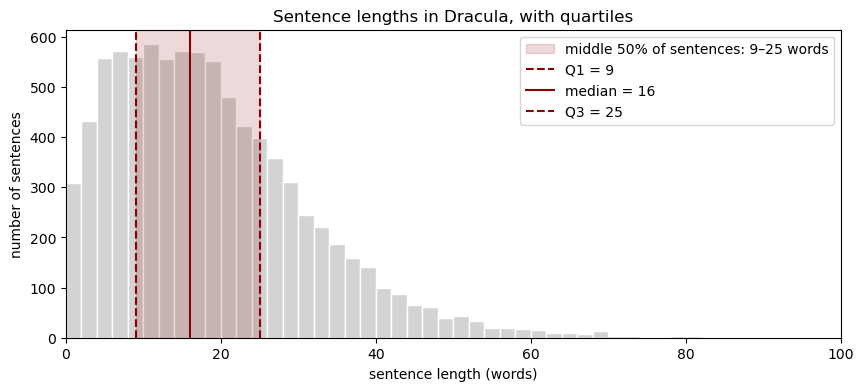

In [12]:
q1 = dracula_lengths.quantile(0.25)
median = dracula_lengths.median()
q3 = dracula_lengths.quantile(0.75)

plt.figure(figsize=(10, 4))
plt.hist(dracula_lengths, bins=range(0, 101, 2), color="lightgray", edgecolor="white")

# shade the middle 50% of sentences
plt.axvspan(q1, q3, color="darkred", alpha=0.15, label=f"middle 50% of sentences: {q1:.0f}–{q3:.0f} words")

# mark Q1, the median and Q3
plt.axvline(q1, color="darkred", linestyle="--", label=f"Q1 = {q1:.0f}")
plt.axvline(median, color="darkred", linestyle="-", label=f"median = {median:.0f}")
plt.axvline(q3, color="darkred", linestyle="--", label=f"Q3 = {q3:.0f}")

plt.xlim(0, 100)
plt.xlabel("sentence length (words)")
plt.ylabel("number of sentences")
plt.title("Sentence lengths in Dracula, with quartiles")
plt.legend()
plt.show()

**Explanation**

`plt.axvspan(q1, q3, ...)` shades the area between Q1 and Q3: the middle 50% of all sentences, which is the IQR. alpha=0.15 makes the shading see-through, so the bars still show.

`plt.axvline(...)` draws a vertical line at each quartile. Dashed lines mark Q1 and Q3; the solid line marks the median.

Each line has a label, so `plt.legend()` lists them in a box. That’s less cluttered than writing text on the plot itself.

> We will talk more about visiualization in the coming weeks!


### `.describe()`, revisited

You've used `.describe()` since the pandas notebook. Now you can read every line of it.

In [ ]:
dracula_lengths.describe().round(2)

| Row | Meaning |
|---|---|
| `count` | how many values (here, sentences) |
| `mean` | the average |
| `std` | standard deviation (the pandas *n − 1* version) |
| `min` / `max` | the extremes, so `max - min` is the range |
| `25%` / `50%` / `75%` | Q1, median, Q3 |

Everything we've covered so far, in one line of code.

---
## 5. Seeing distributions: bar charts, histograms, boxplots

Numbers summarise; pictures show the shape. First, let's put the sentence lengths for **all six** texts into one DataFrame, with one row per sentence.

`.explode()` is new: it takes a column of lists and gives each list item its own row. It's the DataFrame version of the `chain.from_iterable()` flattening we did in the Montagu notebook.

In [18]:
sentences = novels[["title", "sent_lengths"]].explode("sent_lengths").reset_index(drop=True)
sentences = sentences.rename(columns={"sent_lengths": "length"})
sentences["length"] = sentences["length"].astype(int)

print(sentences.shape)
sentences.head()

(26152, 2)


,title,length
0,Frankenstein,43
1,Frankenstein,1
2,Frankenstein,23
3,Frankenstein,26
4,Frankenstein,35


26152 rows in this df mean that there is one row for each sentence. Let's verify:

In [16]:
print("total sentences in all novels:", novels["n_sentences"].sum())

total sentences in all novels: 26152


Now a `groupby` gives us a `.describe()` per novel:

In [24]:
sentences.groupby("title")["length"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
title,,,,,,,,
Carmilla,1465.0,19.3,15.0,1.0,8.0,15.0,26.0,104.0
Dorian Gray,6555.0,12.1,12.2,1.0,6.0,9.0,15.0,457.0
Dracula,8751.0,18.4,12.9,1.0,9.0,16.0,25.0,155.0
Frankenstein,3324.0,22.6,14.2,1.0,13.0,20.0,30.0,156.0
Jekyll and Hyde,1191.0,21.5,17.3,1.0,9.0,17.0,30.0,115.0
The Jewel of Seven Stars,4866.0,18.4,11.4,1.0,10.0,17.0,25.0,139.0


### Bar chart or histogram?

You've already made a lot of **bar charts**: every `FreqDist(...).plot()` in the Montagu notebook was one. A bar chart has one bar per **category** (a word, a POS tag, a novel), and the order of the bars is up to you.

A **histogram** is for **numbers**. It cuts the number line into bins (0–5 words, 5–10 words, …) and draws a bar for how many values fall into each bin. The order of the bins is fixed, and the bars touch, because the bins are next to each other on the number line.

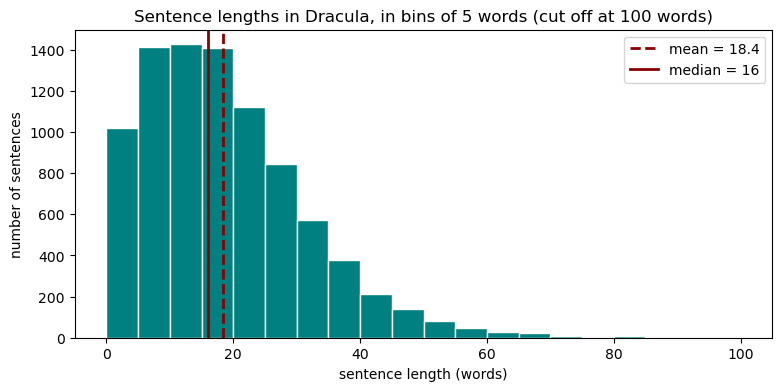

In [19]:
plt.figure(figsize=(9, 4))
plt.hist(dracula_lengths, bins=range(0, 105, 5), color="teal", edgecolor="white")
plt.axvline(dracula_lengths.mean(), color="darkred", linestyle="--", linewidth=2, label=f"mean = {dracula_lengths.mean():.1f}")
plt.axvline(dracula_lengths.median(), color="darkred", linestyle="-", linewidth=2, label=f"median = {dracula_lengths.median():.0f}")

plt.xlabel("sentence length (words)")
plt.ylabel("number of sentences")
plt.title("Sentence lengths in Dracula, in bins of 5 words (cut off at 100 words)")
plt.legend()
plt.show()

Remember the bar chart in Section 3, with one bar for every sentence length? That’s fine when there are a few dozen values, but it gets crowded. A histogram groups the values into bins. Here, each bar counts all sentences between 0–5 words, 5–10 words, and so on.

### Skew

This distribution is lopsided. Most sentences are short or medium, and a long **tail** stretches out to the right. We call this **right-skewed** (or *positively skewed*). In a right-skewed distribution, the mean sits to the right of the median: the tail drags it along. That's the picture behind the outlier example in Section 3.

Almost everything we count in texts is right-skewed: sentence lengths, letter lengths, word frequencies. Keep that in mind whenever you report an average.

### Boxplots

A **boxplot** draws the quartiles directly, which makes it easy to compare several groups side by side:

- the **box** goes from Q1 to Q3 (the IQR)
- the **line inside** the box is the median
- the **whiskers** reach out to the most extreme values within 1.5 × IQR of the box
- **dots** beyond the whiskers are potential outliers (we hide them here to keep the plot readable)

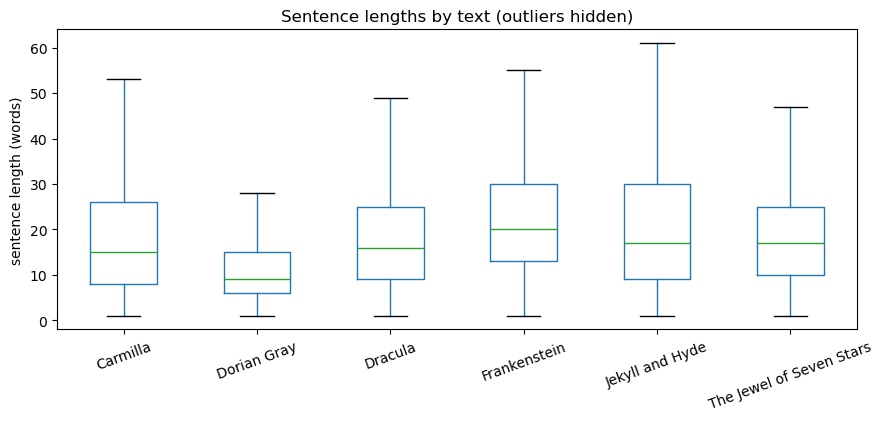

In [22]:
sentences.boxplot(column="length", by="title", showfliers=False, figsize=(10, 4))

plt.grid(False)       # no grid
plt.ylabel("sentence length (words)")
plt.xlabel("")
plt.title("Sentence lengths by text (outliers hidden)")
plt.suptitle("")      # remove pandas' automatic extra title
plt.xticks(rotation=20)
plt.show()

In case you were wondering why we hid the outliers:

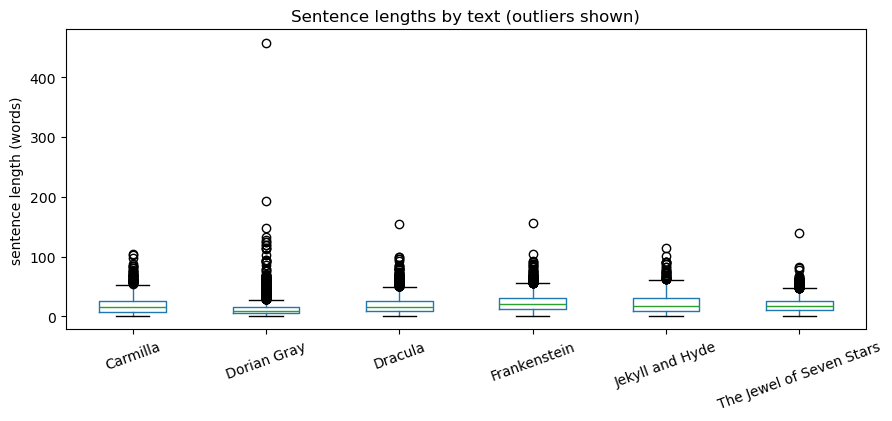

In [23]:
sentences.boxplot(column="length", by="title", showfliers=True, figsize=(10, 4))

plt.grid(False)       # no grid
plt.ylabel("sentence length (words)")
plt.xlabel("")
plt.title("Sentence lengths by text (outliers shown)")
plt.suptitle("")      # remove pandas' automatic extra title
plt.xticks(rotation=20)
plt.show()

> Remember the 456-word sentence in Dorian Gray? 

With the outliers on, the y-axis has to stretch all the way up to fit them. The boxes get squashed at the bottom and are hard to compare. The stuff that we are actually interested in remains hidden.

Hiding the outliers only changes the picture, not the data. The long sentences are still in sentences, and the medians and quartiles are exactly the same in both plots. Whenever you hide something in a plot, say so, which is why the title says “(outliers hidden). You don't have to add it to the title but make sure that it is in your description.

<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  Which text has the shortest typical sentences? Which has the longest? Which is the most variable? Check your answers against the <code>groupby</code> table above.
</div>

| title | count | mean | std | min | 25% | 50% | 75% | max |
|---|---|---|---|---|---|---|---|---|
| Carmilla | 1465 | 19.3 | 15.0 | 1 | 8 | 15 | 26 | 104 |
| Dorian Gray | 6555 | 12.1 | 12.2 | 1 | 6 | **9** | 15 | **457** |
| Dracula | 8751 | 18.4 | 12.9 | 1 | 9 | 16 | 25 | 155 |
| Frankenstein | 3324 | 22.6 | 14.2 | 1 | 13 | **20** | 30 | 156 |
| Jekyll and Hyde | 1191 | 21.5 | **17.3** | 1 | 9 | 17 | 30 | 115 |
| The Jewel of Seven Stars | 4866 | 18.4 | 11.4 | 1 | 10 | 17 | 25 | 139 |

*Dorian Gray* has by far the shortest median sentence (9 words), but look at its row in the table: its standard deviation (12.2 words) is roughly as large as its mean (12.1 words). Short sentences most of the time, with the occasional enormous one. 

*Frankenstein*'s long sentences sit at the other end, with the highest median (20 words). 

In [25]:
# let's compute coefficient of variation (CV)
summary = sentences.groupby("title")["length"].describe()
(summary["std"] / summary["mean"]).sort_values(ascending=False).round(2)

title
Dorian Gray                 1.01
Jekyll and Hyde             0.80
Carmilla                    0.78
Dracula                     0.70
Frankenstein                0.63
The Jewel of Seven Stars    0.62
dtype: float64

By raw standard deviation (17.3 words), *Jekyll and Hyde* is the most variable. But "most variable" depends on how you measure it: the standard deviation answers *in words*, the coefficient of variation (0.8 or 80%) answers *relative to the typical length*. 

*Dorian Gray* has a CV of 1.01 or 101%, so the typical distance from the average is about as big as the average itself. A large CV tells us that Dorian Gray has an unusual mix of very short and very long sentences. But it’s sensitive to outliers: a few enormous sentences are responsible for much of it. So it’s a reason to go and look at those sentences. What purpose do they serve for Wilde's narrative?



---
## 6. Zipf's law, the long tail, and logarithms

Now let's look at the distribution of **word frequencies**: how often each type appears. We'll use *Dracula*, and rank every word from most to least frequent with `FreqDist`.

In [30]:
all_tokens = [token for tokens in novels["tokens"] for token in tokens]
corpus_fd = FreqDist(all_tokens)

print("tokens:", corpus_fd.N())
print("types: ", len(corpus_fd))
corpus_fd.most_common(20)

tokens: 459102
types:  17136


[('the', 24399),
 ('and', 15614),
 ('i', 13200),
 ('of', 12971),
 ('to', 12303),
 ('a', 9079),
 ('in', 7602),
 ('that', 6973),
 ('was', 6319),
 ('he', 6248),
 ('it', 6131),
 ('my', 4665),
 ('you', 4587),
 ('as', 4138),
 ('his', 4016),
 ('had', 4010),
 ('with', 3903),
 ('me', 3772),
 ('for', 3654),
 ('is', 3651)]

*Explanation*

`[token for tokens in novels["tokens"] for token in tokens]` is a list comprehension with two `for`s. Read it like nested loops: *for each list of tokens in the column, for each token in that list, keep the token.* It flattens all six token lists into one big list, just like `chain.from_iterable()` did in the Montagu notebook.

`corpus_fd.N()` gives the total number of tokens, and `len(corpus_fd)` the number of types.

The top of the list is all function words, the ones on our stopword list. Let's plot the 50 most frequent words.

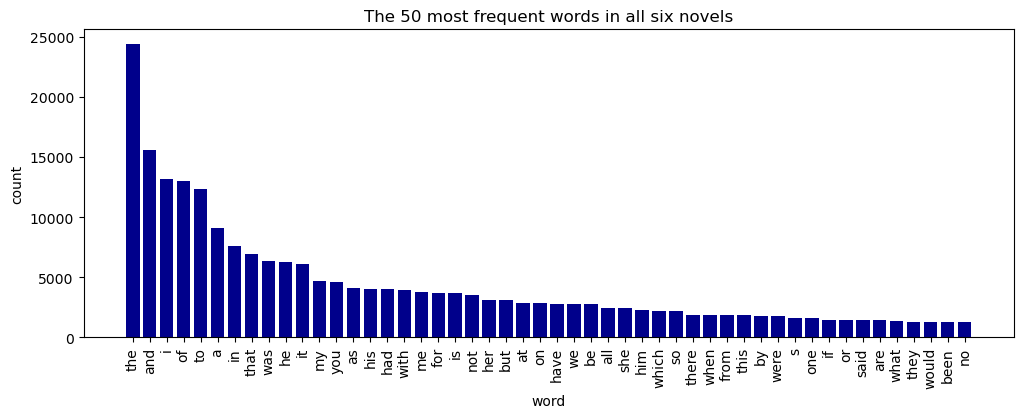

In [34]:
top_50 = corpus_fd.most_common(50)
words, counts = zip(*top_50)

plt.figure(figsize=(12, 4))
plt.bar(words, counts, color="darkblue")
plt.xticks(rotation=90)
plt.xlabel("word")
plt.ylabel("count")
plt.title("The 50 most frequent words in all six novels")
plt.show()


How big a share of the text is *the* alone?

In [35]:
the_share = corpus_fd["the"] / corpus_fd.N()
print(f"The most frequent word, 'the', is {the_share:.1%} of all tokens in all six novels")

The most frequent word, 'the', is 5.3% of all tokens in all six novels


`corpus_fd.N()` is the total number of tokens in a `FreqDist`. 

For comparison, in the Montagu letters *the* was 3,438 of 59,163 tokens, about 5.8%. Two very different texts, a very similar proportion.


### Zipf's law

In the 1930s and 40s the linguist George Kingsley Zipf noticed a pattern: a word's frequency is roughly **inversely proportional to its rank**. The 2nd most common word appears about half as often as the 1st, the 3rd about a third as often, the 10th about a tenth, and so on.

In other words, a word's frequency is roughly **1 divided by its rank**.

![img](../../img/zipfwiki.png)

Image from this [website](http://wugology.com/zipfs-law/)

This is not a law in the way gravity is a law. Real texts never follow it exactly. But the overall shape is remarkably consistent: a **few** words are extremely common, and **most** words are rare.

Let's see what our whole corpus looks like, with every word, not just the top 50.

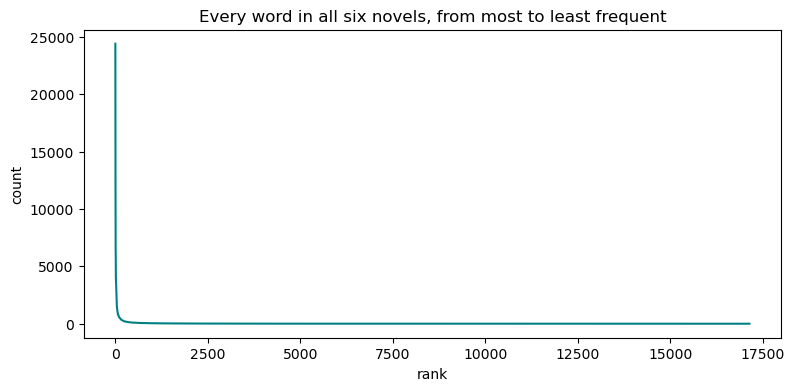

In [36]:
counts = [count for word, count in corpus_fd.most_common()]
ranks = range(1, len(counts) + 1)

plt.figure(figsize=(9, 4))
plt.plot(ranks, counts, color="teal")
plt.xlabel("rank")
plt.ylabel("count")
plt.title("Every word in all six novels, from most to least frequent")
plt.show()

This plot is nearly useless: a huge spike on the left, then a flat line hugging the bottom. With more than 17,000 words, the rare ones are squashed against the axis.

The fix is to use a **logarithmic scale** (log scale). On a normal axis, each step adds the same amount: 0, 10,000, 20,000, 30,000. On a log scale, each step **multiplies** by 10: 1, 10, 100, 1,000, 10,000. That way, a word that appears 10,000 times and a word that appears once can fit on the same plot.

On a **log-log** scale, the plot becomes something close to a straight line. That straight line *is* Zipf's law.

`plt.loglog()` draws a plot with a log scale on **both** axes.

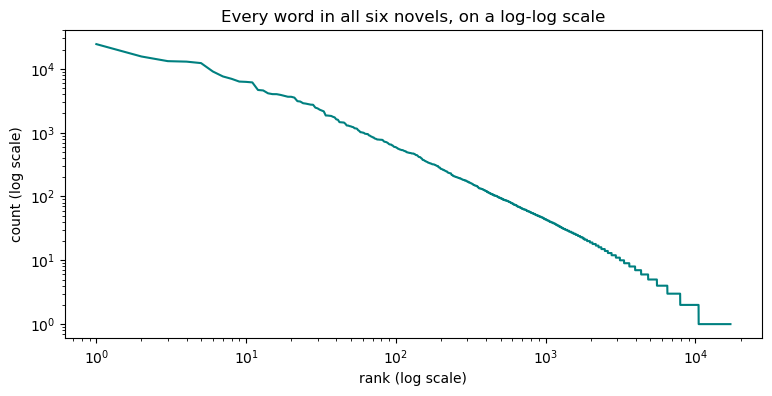

In [37]:
plt.figure(figsize=(9, 4))
plt.loglog(ranks, counts, color="teal")
plt.xlabel("rank (log scale)")
plt.ylabel("count (log scale)")
plt.title("Every word in all six novels, on a log-log scale")
plt.show()

So on a log scale, going from 10 to 100 to 1,000 is three **equal** steps. A logarithm turns *multiplying* into *adding*. That makes it the natural tool for data that spans many orders of magnitude, like word counts that run from about 8,000 down to 1.

You'll meet the logarithm again very soon: the **IDF** in TF-IDF is a logarithm, used for exactly this reason. And we'll look at logarithms more closely in the NumPy notebook.

### Is it the same for every novel?

Let's draw one line per novel on the same plot.

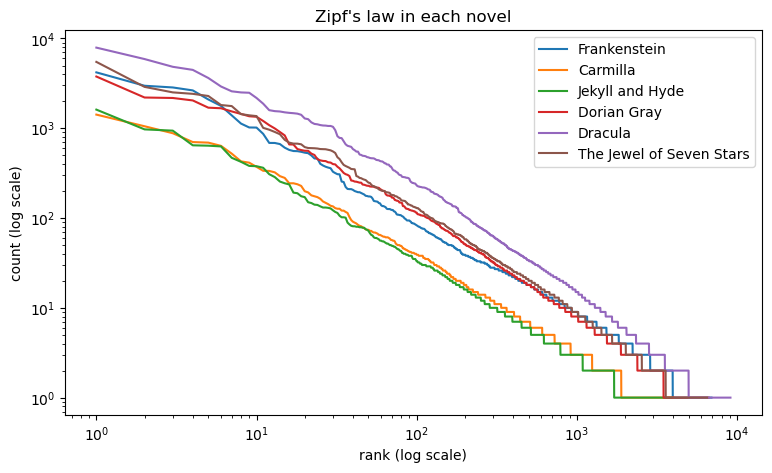

In [38]:
plt.figure(figsize=(9, 5))

for _, novel in novels.iterrows():
    counts = [count for word, count in FreqDist(novel["tokens"]).most_common()]
    ranks = range(1, len(counts) + 1)
    plt.loglog(ranks, counts, label=novel["title"])

plt.xlabel("rank (log scale)")
plt.ylabel("count (log scale)")
plt.title("Zipf's law in each novel")
plt.legend()
plt.show()

*Explanation*

For each novel, we make a `FreqDist` of its tokens, sort the counts from highest to lowest, and draw them on a log-log plot. Because each `plt.loglog()` call has a `label`, `plt.legend()` can tell us which line is which.

<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  Six different authors, six different stories, very different lengths. What do the lines have in common? What's different?
</div>

The lines are at different **heights**: longer novels like *Dracula* have higher counts for every rank, simply because they have more words, and the short ones (*Carmilla*, *Jekyll and Hyde*) sit lower. But the **shape** and the **slope** are almost identical. Whoever wrote the text and whatever it is about, the same pattern appears: a few very frequent words, and a long tail of rare ones.

> 💡 **Most words are rare, and most text is made of a few common words.** That is why stopwords make up so much of every text, and why so many words appear only once or twice.

### The long tail and hapax legomena

The flip side of a few very frequent words is a **very long tail** of rare words. A word that appears exactly once in a text is called a **hapax legomenon** (Greek for "said once"; plural *hapax legomena*). Philologists have studied them for centuries, in Homer, in Shakespeare, in Federalist Papers.

You've already seen hapaxes: they were most of the "least common words" we printed in the Montagu notebook.

In [39]:
dracula_fd = FreqDist(novels.loc[4, "tokens"])

In [40]:
hapaxes = dracula_fd.hapaxes()     # FreqDist has a method just for this!

print("types in Dracula:   ", len(dracula_fd))
print("hapax legomena:     ", len(hapaxes))
print(f"share of types:      {len(hapaxes) / len(dracula_fd):.1%}")
print(f"share of tokens:     {len(hapaxes) / dracula_fd.N():.1%}")

types in Dracula:    9097
hapax legomena:      4115
share of types:      45.2%
share of tokens:     2.6%


In [41]:
# a few of Stoker's hapaxes
sorted(hapaxes)[1000:1020]

['despairingly',
 'despatch',
 'despicable',
 'despise',
 'despises',
 'despondently',
 'dessay',
 'destinations',
 'destined',
 'detain',
 'detective',
 'detrimentally',
 'deux',
 'deviate',
 'devotedly',
 'devoutly',
 'dexterity',
 'diabolic',
 'diabolically',
 'diagnosed']

Nearly **half** of the distinct words in *Dracula* appear only once, yet together they make up only a few percent of the running text. This is the shape of almost every text, in almost every language:

> **Most words are rare, and most text is made of a few common words.**

This has practical consequences. For many types we have almost no evidence: one occurrence. That's why methods like TF-IDF and word2vec usually ignore words below a minimum count, and why the very common words need special treatment too.

---
## 7. Lexical diversity: the type-token ratio and its traps

How "rich" is an author's vocabulary? A common first measure is the **type-token ratio** (TTR):

$$\text{TTR} = \frac{\text{number of types}}{\text{number of tokens}}$$

A TTR close to 1 means almost every word is new; close to 0 means the same words are repeated over and over.

In [42]:
novels["n_types"] = novels["tokens"].apply(lambda tokens: len(set(tokens)))
novels["ttr"] = novels["n_types"] / novels["n_tokens"]

novels[["title", "n_tokens", "n_types", "ttr"]].sort_values("ttr", ascending=False).round(3)

,title,n_tokens,n_types,ttr
2,Jekyll and Hyde,25642,3877,0.151
1,Carmilla,28270,3991,0.141
0,Frankenstein,75028,6923,0.092
3,Dorian Gray,79283,6642,0.084
5,The Jewel of Seven Stars,89756,6496,0.072
4,Dracula,161123,9097,0.056


<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  According to TTR, <em>Jekyll and Hyde</em> has the richest vocabulary and <em>Dracula</em> the poorest. Do you believe this?
</div>

You shouldn't, at least not yet. Look at the `n_tokens` column: the ranking is exactly the **reverse of the text lengths**. TTR has a hidden dependence on length. The longer a text gets, the more likely each new token is a word you've already seen (remember Zipf: the same few words keep coming back), so the TTR keeps falling.

We can watch this happen by computing the TTR of just the first *N* tokens of each text.

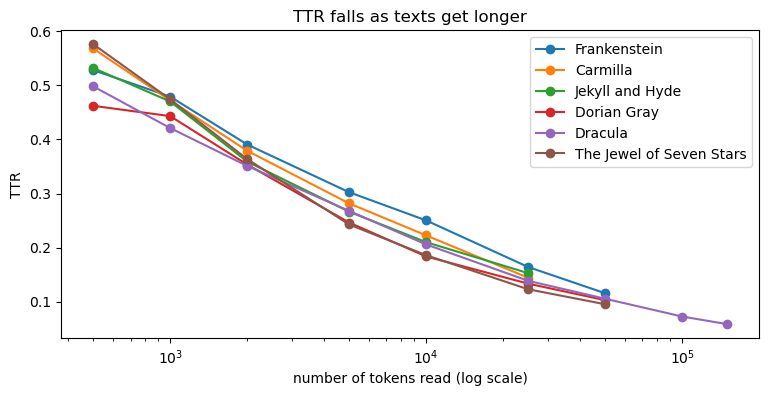

In [43]:
sizes = [500, 1_000, 2_000, 5_000, 10_000, 25_000, 50_000, 100_000, 150_000]

fig, ax = plt.subplots(figsize=(9, 4))

for _, novel in novels.iterrows():
    tokens = novel["tokens"]
    xs = [n for n in sizes if n <= len(tokens)]            # only sizes the text is long enough for
    ys = [len(set(tokens[:n])) / n for n in xs]            # TTR of the first n tokens
    ax.plot(xs, ys, marker="o", label=novel["title"])

ax.set_xscale("log")
ax.set_xlabel("number of tokens read (log scale)")
ax.set_ylabel("TTR")
ax.set_title("TTR falls as texts get longer")
ax.legend()
plt.show()

Every line slopes downwards. Comparing the TTR of the 26,000-word *Jekyll and Hyde* with the 160,000-word *Dracula* compares two different points on these curves, not two vocabularies.

### A fairer version: standardised TTR

One fix is to **hold length constant**. Cut every text into chunks of the same size (say, 1,000 tokens), compute the TTR of each chunk, then take the mean. This is called the **standardised type-token ratio** (STTR).

In [44]:
def sttr(tokens, chunk_size=1000):
    """Mean TTR over consecutive chunks of chunk_size tokens."""
    ratios = []
    for start in range(0, len(tokens) - chunk_size + 1, chunk_size):
        chunk = tokens[start:start + chunk_size]
        ratios.append(len(set(chunk)) / chunk_size)
    return sum(ratios) / len(ratios)

novels["sttr"] = novels["tokens"].apply(sttr)

novels[["title", "n_tokens", "ttr", "sttr"]].sort_values("sttr", ascending=False).round(3)

,title,n_tokens,ttr,sttr
0,Frankenstein,75028,0.092,0.441
1,Carmilla,28270,0.141,0.430
2,Jekyll and Hyde,25642,0.151,0.425
3,Dorian Gray,79283,0.084,0.416
5,The Jewel of Seven Stars,89756,0.072,0.398
4,Dracula,161123,0.056,0.393


*Explanation*

- `range(0, len(tokens) - chunk_size + 1, chunk_size)` gives us the starting position of each chunk: 0, 1000, 2000… We stop early enough that the last chunk is still a full 1,000 tokens (a shorter last chunk would get an unfairly high TTR).
- `tokens[start:start + chunk_size]` slices out one chunk, just like slicing any list.
- We compute each chunk's TTR and then the mean of all of them.

The ranking changes. *Frankenstein* now comes first, and *Jekyll and Hyde* is no longer at the top. *Dracula* is still last, but the gap between it and the others is much smaller than plain TTR suggested.

> ⚠️ **The big lesson of this section:** before you trust any measure, ask *does this depend on the length of the text?* Many do. Normalising (Section 2) and holding size constant (here) are the two standard fixes.

---
## 8. Standardising with z-scores

Sometimes we want to know how **unusual** a value is. Is a 60-word sentence long for Stoker? A **z-score** answers this by measuring how far a value is from the mean **in units of standard deviations**:

$$z = \frac{\text{value} - \text{mean}}{\text{standard deviation}}$$

- z = 0: exactly average
- z = 1: one standard deviation above average
- z = −2: two standard deviations below average

In [ ]:
mean_len = dracula_lengths.mean()
std_len = dracula_lengths.std()

for x in [8, 18, 40, 60, 120]:
    z = (x - mean_len) / std_len
    print(f"a {x:>3}-word sentence in Dracula has z = {z:5.2f}")

A 60-word sentence is more than three standard deviations above *Dracula*'s average: genuinely unusual for this book.

### Why z-scores matter for comparing words

Z-scores also let us compare things measured on totally different scales. *the* occurs hundreds of times per 10,000 words; *my* occurs a few dozen times. A difference of 10 per 10,000 is tiny for *the* but huge for *my*. Converting to z-scores puts every word on the **same scale**: "how unusual is this text, for this word?"

Let's find the 30 most frequent words across our whole corpus. Unsurprisingly, they're nearly all stopwords.

In [ ]:
all_tokens = [token for tokens in novels["tokens"] for token in tokens]
corpus_fd = FreqDist(all_tokens)

top_words = [word for word, count in corpus_fd.most_common(30)]
print(top_words)

*Explanation*

`[token for tokens in novels["tokens"] for token in tokens]` is a list comprehension with two `for`s. Read it left to right like nested loops: *for each list of tokens in the column, for each token in that list, keep the token.* It flattens the column into one big list (another way to do what `chain.from_iterable()` did).

Next, a table of relative frequencies: one row per novel, one column per word, values per 1,000 words.

In [ ]:
rows = []
for _, novel in novels.iterrows():
    counts = Counter(novel["tokens"])
    row = {word: counts[word] / novel["n_tokens"] * 1000 for word in top_words}
    row["title"] = novel["title"]
    rows.append(row)

top_freq = pd.DataFrame(rows).set_index("title")
top_freq.iloc[:, :10].round(1)       # the first 10 columns

Now we turn each column into z-scores: for each word, subtract that word's mean across the six texts and divide by its standard deviation. pandas does this column by column automatically, in one line.

In [ ]:
z_scores = (top_freq - top_freq.mean()) / top_freq.std()
z_scores.iloc[:, :10].round(2)

*Explanation*

- `top_freq.mean()` gives one mean **per column** (per word).
- `top_freq - top_freq.mean()` subtracts each column's own mean from that column.
- The same happens with `.std()`. The result: every column now has a mean of 0 and a standard deviation of 1.

Let's pull out just the pronouns:

In [ ]:
z_scores[["i", "my", "me", "we", "she", "he"]].round(2)

<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  Which text uses the first person singular (<em>i, my, me</em>) the most? Which uses <em>we</em> the most? Does that fit what you know about how these books are narrated?
</div>

*Frankenstein* is told by a chain of first-person narrators (Walton, Victor, the creature), and it stands out on all three. *Dracula* leads on *we*: much of it is narrated by a group of friends hunting the Count together. Keep an eye on that *we* in the next experiment.

### Putting it together: a tiny authorship experiment

In 2002 the literary scholar John Burrows proposed a way of measuring stylistic distance, now known as **Burrows's Delta**. It's one of the classic methods of DH stylometry, still used in authorship attribution. And it's surprisingly simple:

1. Take the most frequent words in the corpus (mostly function words, the very words we usually *remove* as stopwords!).
2. Convert their relative frequencies to z-scores.
3. The distance between two texts is the **mean absolute difference** between their z-scores.

Small Delta = similar style. We already have steps 1 and 2.

In [ ]:
def delta(title_a, title_b):
    """Burrows's Delta between two texts in the z_scores table."""
    differences = z_scores.loc[title_a] - z_scores.loc[title_b]
    return differences.abs().mean()

delta("Dracula", "Frankenstein")

*Explanation*

- `z_scores.loc[title_a]` is one row: that text's 30 z-scores.
- Subtracting two rows gives 30 differences, one per word.
- `.abs()` makes them all positive (we care about *how different*, not in which direction), and `.mean()` averages them.

Now every pair of texts:

In [ ]:
titles = z_scores.index

delta_table = pd.DataFrame(index=titles, columns=titles, dtype=float)
for a in titles:
    for b in titles:
        delta_table.loc[a, b] = delta(a, b)

delta_table.round(2)

In [ ]:
# For each text, which other text is stylistically closest?
for title in titles:
    closest = delta_table.loc[title].drop(title).idxmin()
    print(f"{title:<26} -> {closest}")

<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  What happened to the two Stoker novels?
</div>

With nothing but 30 very common words, and without being told who wrote what, *Dracula* and *The Jewel of Seven Stars* pick each other out. Part of the reason is that *we* column: both Stoker novels are about a small group of people watching and acting together. That's despite the fact that they tell very different stories (a vampire in Transylvania and London; an Egyptian mummy in London and Cornwall) and are told in different ways.

With six texts this is of course a toy. Real authorship studies use hundreds of words and many texts per author, and Delta can be fooled by genre, period and narration. But the logic is exactly the same.

> 💡 Notice the twist: stopwords, which we often throw away as "noise", carry a strong **authorial signal**. Whether to remove them depends entirely on your question. They are, once again, design decisions.

---
## 9. Putting it together: statistics on POS tags

Everything in this notebook works on *any* count, not just words. Let's apply it to something you've been producing yourselves: **part-of-speech tags**.

As in the Montagu notebook, we tag the original text (POS taggers work better with capitalisation and punctuation), store the tags in a column, and only afterwards keep alphabetic tokens. This cell takes a little while to run.

In [ ]:
novels["pos_tags"] = novels["text"].apply(lambda text: pos_tag(word_tokenize(text)))

novels.loc[1, "pos_tags"][200:215]

Now we turn the tags into **proportions**: what share of each text's words are nouns, verbs, adjectives, adverbs and pronouns? Notice that this is Section 2 again: we can't compare raw noun counts across texts of different lengths.

In [ ]:
pos_groups = {
    "noun":      ("NN",),          # NN, NNS, NNP, NNPS
    "verb":      ("VB",),          # VB, VBD, VBG, VBN, VBP, VBZ
    "adjective": ("JJ",),          # JJ, JJR, JJS
    "adverb":    ("RB",),          # RB, RBR, RBS
    "pronoun":   ("PRP",),         # PRP, PRP$
}

def pos_shares(tagged):
    """Percentage of alphabetic tokens in each POS group."""
    tags = [tag for word, tag in tagged if word.isalpha()]
    shares = {}
    for group, prefixes in pos_groups.items():
        n = sum(1 for tag in tags if tag.startswith(prefixes))
        shares[group] = n / len(tags) * 100
    return pd.Series(shares)

pos_table = novels["pos_tags"].apply(pos_shares)
pos_table.index = novels["title"]
pos_table.round(1)

*Explanation*

- `pos_groups` maps a readable name to the tag prefixes that belong to it. `tag.startswith("NN")` is True for `NN`, `NNS`, `NNP` and `NNPS`, just like the `noun_tags` set we used for Montagu.
- When `.apply()` returns a pandas Series for each row, pandas assembles the results into a DataFrame: one row per novel, one column per POS group.

Let's plot it. This time a **bar chart** is the right choice, because the POS groups are categories.

In [ ]:
pos_table.plot(kind="bar", figsize=(10, 4))
plt.ylabel("% of tokens")
plt.xlabel("")
plt.title("Part-of-speech proportions")
plt.xticks(rotation=20)
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  At first glance, the six texts look very similar. Are they?
</div>

They are fairly similar: roughly a fifth of every text is nouns, a fifth verbs, and so on. That's English grammar at work. But "fairly similar" doesn't mean "the same", and this is exactly the situation where z-scores help: they zoom in on the **differences**.

In [ ]:
pos_z = (pos_table - pos_table.mean()) / pos_table.std()
pos_z.round(2)

Some things worth noticing:

- *Dorian Gray* has the highest z-scores for **verbs** and **adjectives**: lots of dialogue, and Wilde's famously ornamental descriptions.
- *Jekyll and Hyde* has the most **nouns** and the fewest **pronouns**. Stevenson's narrator keeps naming people and things (*the lawyer*, *the door*, *the street*) rather than saying *he* or *it*.
- *Dracula* has the fewest nouns and adjectives. Diaries and letters are full of *I*, *we* and verbs of doing; there's less room for description.

> ⚠️ **A word of caution.** Z-scores make differences look dramatic, whatever their size. A z-score of 1.5 here can correspond to a difference of just one or two percentage points. Always look at the raw proportions *and* the z-scores together. And remember that with only six texts, these are descriptions of our six texts, not laws about Gothic fiction.

---
## 10. Practice Challenges

<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  Challenge 1: Using the <code>sentences</code> DataFrame, find the mean and the median sentence length in <em>Dorian Gray</em>. Which better describes a "typical" sentence, and why are they so different?
</div>

In [ ]:
### YOUR CODE HERE

In [ ]:
dorian = sentences[sentences["title"] == "Dorian Gray"]["length"]

print("mean:  ", round(dorian.mean(), 2))
print("median:", dorian.median())
print("max:   ", dorian.max())

**Answer:** The median is lower than the mean. Most of Wilde's sentences are short (dialogue, epigrams), but a few enormous ones, like the 456-word catalogue in Chapter 11, drag the mean upwards. The median is a better description of a typical sentence in this book.

<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  Challenge 2: Choose three words that you think are typically Gothic (not the ones we used!). Compute their frequency per 10,000 words in each text. Then compare with raw counts: does normalising change the ranking?
</div>

In [ ]:
### YOUR CODE HERE

In [ ]:
my_words = ["castle", "ghost", "strange"]

rows = []
for _, novel in novels.iterrows():
    counts = Counter(novel["tokens"])
    for word in my_words:
        rows.append({
            "title": novel["title"],
            "word": word,
            "raw": counts[word],
            "per_10k": round(counts[word] / novel["n_tokens"] * 10_000, 1),
        })

pd.DataFrame(rows).sort_values(["word", "per_10k"], ascending=[True, False])

**Answer:** It depends on your words. With *castle*, *ghost* and *strange*: *Dracula* has the most raw *castle*s, but per 10,000 words *Carmilla* (set in a Styrian castle) wins. Long texts tend to top raw counts, and the ranking shifts once you normalise. Notice also how many zeros there are: for rare words, a difference between 0 and 1 occurrences says very little.

<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  Challenge 3: You've been removing stopwords in your own work. What share of each text's tokens are stopwords (using NLTK's list)?
</div>

In [ ]:
### YOUR CODE HERE

In [ ]:
novels["stopword_share"] = novels["tokens"].apply(
    lambda tokens: sum(1 for t in tokens if t in stop_words) / len(tokens)
)

novels[["title", "stopword_share"]].sort_values("stopword_share", ascending=False).round(3)

**Answer:** In every text, more than half of all tokens are stopwords. That's Zipf's law in action: a short list of types covers a huge share of the tokens. It also means that removing stopwords cuts your token counts roughly in half, which changes every relative frequency you calculate afterwards. Always decide (and report!) whether your counts were made before or after stopword removal.

<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  Challenge 4: Does lemmatizing change lexical diversity? Lemmatize <em>Carmilla</em> using the functions from the Montagu notebook, then compare the number of types and the STTR before and after.
</div>

In [ ]:
### YOUR CODE HERE

In [ ]:
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet

lemmatizer = WordNetLemmatizer()

# the same helper functions as in the Montagu notebook
def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

def lemmatize_text(pos_tag_list):
    lemmas = []
    for word, tag in pos_tag_list:
        if word.isalpha():
            lemmas.append(lemmatizer.lemmatize(word.lower(), get_wordnet_pos(tag)))
    return lemmas

carmilla_tokens = novels.loc[1, "tokens"]
carmilla_lemmas = lemmatize_text(novels.loc[1, "pos_tags"])

print("types (tokens):", len(set(carmilla_tokens)), "  STTR:", round(sttr(carmilla_tokens), 3))
print("types (lemmas):", len(set(carmilla_lemmas)), "  STTR:", round(sttr(carmilla_lemmas), 3))

**Answer:** Lemmatizing merges forms like *was / were / is* or *eye / eyes* into one type, so the number of types drops and so does the STTR. Neither number is "the right one": they measure slightly different things (variety of word *forms* vs. variety of *dictionary words*). Another design decision to report.

<div style="background: rgba(167, 139, 250, 0.12); border-radius: 6px; padding: 0.6em 1em; margin: 1.5em 0; font-weight: 500;">
  Challenge 5: Repeat the Burrows's Delta experiment, but this time use the 30 most frequent words <b>after removing stopwords</b>. Do the two Stoker novels still find each other?
</div>

In [ ]:
### YOUR CODE HERE

In [ ]:
content_fd = FreqDist([t for t in all_tokens if t not in stop_words])
content_words = [word for word, count in content_fd.most_common(30)]
print(content_words, "\n")

rows = []
for _, novel in novels.iterrows():
    counts = Counter(novel["tokens"])
    row = {word: counts[word] / novel["n_tokens"] * 1000 for word in content_words}
    row["title"] = novel["title"]
    rows.append(row)

content_freq = pd.DataFrame(rows).set_index("title")
content_z = (content_freq - content_freq.mean()) / content_freq.std()

for a in content_z.index:
    distances = {b: (content_z.loc[a] - content_z.loc[b]).abs().mean() for b in content_z.index if b != a}
    print(f"{a:<26} -> {min(distances, key=distances.get)}")

**Answer:** Yes, *Dracula* and *The Jewel of Seven Stars* still pick each other out. Look at the word list, though: *one, said, would, could, us, know, must, shall*… Even after removing stopwords, the most frequent words are still mostly small, everyday words. If you look at `content_z.loc[["Dracula", "The Jewel of Seven Stars"]]`, you'll find that both Stoker novels use more *us*, *could*, *came*, *went* and *time* than the other texts: people moving, watching and acting together. An author's habits live in exactly these unremarkable words.

---
## 11. Key points to remember

| Concept | What it tells you | Code |
|---|---|---|
| Tokens / types | running words / distinct words | `len(tokens)` / `len(set(tokens))` |
| Distribution | how often each value occurs | `FreqDist(...)`, `.value_counts()` |
| Relative frequency | count normalised by length; comparable across texts | `count / n_tokens * 10_000` |
| Mean | the average; pulled by outliers | `s.mean()` |
| Median | the middle value; robust to outliers | `s.median()` |
| Mode | the most common value; good for spotting patterns and quirks | `s.mode()` |
| Standard deviation | typical distance from the mean | `s.std()` |
| Coefficient of variation | spread relative to the mean | `s.std() / s.mean()` |
| Quartiles / IQR | spread of the middle 50% | `s.quantile(0.25)`, `s.quantile(0.75)` |
| Summary table | all of the above at once | `s.describe()` |
| Bar chart | one bar per **category** | `.plot(kind="bar")` |
| Histogram / boxplot | the shape of a **numeric** distribution | `plt.hist()` / `df.boxplot()` |
| Skew | a long tail on one side; mean pulled towards it | compare mean and median |
| Zipf's law | frequency ≈ 1 / rank; most words are rare | `plt.loglog()` |
| Logarithm | turns multiplying into adding; tames huge ranges | `math.log10(x)` |
| Hapax legomena | words occurring once | `fd.hapaxes()` |
| TTR | types / tokens; **depends on length!** | `len(set(tokens)) / len(tokens)` |
| STTR | TTR averaged over equal-sized chunks | `sttr(tokens)` |
| z-score | how unusual a value is, in standard deviations | `(x - x.mean()) / x.std()` |
| Burrows's Delta | stylistic distance from z-scores of frequent words | `(z_a - z_b).abs().mean()` |

**Three questions to ask of any number in text analysis:**

1. **Compared to what?** (raw vs. relative frequencies; z-scores)
2. **Does it depend on length?** (normalise, or hold length constant)
3. **What does the data behind it actually look like?** (always read some examples)

---
## Save your work

We've added a lot of columns. The token and POS columns are large and easy to recompute, so let's save only the summary statistics.

In [ ]:
summary_cols = ["title", "author", "year", "n_tokens", "n_types", "n_sentences",
                "she_per_10k", "ttr", "sttr"]

novels[summary_cols].to_csv(DATA_DIR + "gothic_novels_stats.csv", index=False)
novels[summary_cols]